In [1]:
import json
import re
from collections import Counter
from itertools import combinations

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import spacy

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

with open("wikipedia_articles.json", "r", encoding="utf-8") as file:
    articles = json.load(file)

print("Number of articles:", len(articles))
print("First five articles:", list(articles.keys())[:5])

nlp = spacy.load("en_core_web_sm")

Number of articles: 200
First five articles: ['World War II', 'United Nations', 'Democracy', 'Cold War', 'European Union']


In [2]:
texts = [article["text"] for article in articles.values()]
titles = list(articles.keys())

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=2
)

tfidf_matrix = vectorizer.fit_transform(texts)
similarity_matrix = cosine_similarity(tfidf_matrix)

G_similarity = nx.Graph()
G_similarity.add_nodes_from(titles)

THRESHOLD = 0.12

for i in range(len(titles)):
    for j in range(i + 1, len(titles)):
        score = similarity_matrix[i, j]

        if score >= THRESHOLD:
            G_similarity.add_edge(
                titles[i],
                titles[j],
                weight=float(score)
            )

print("Article similarity graph")
print("Nodes:", G_similarity.number_of_nodes())
print("Edges:", G_similarity.number_of_edges())
print("Connected components:", nx.number_connected_components(G_similarity))
print("Density:", round(nx.density(G_similarity), 4))

Article similarity graph
Nodes: 200
Edges: 1831
Connected components: 6
Density: 0.092


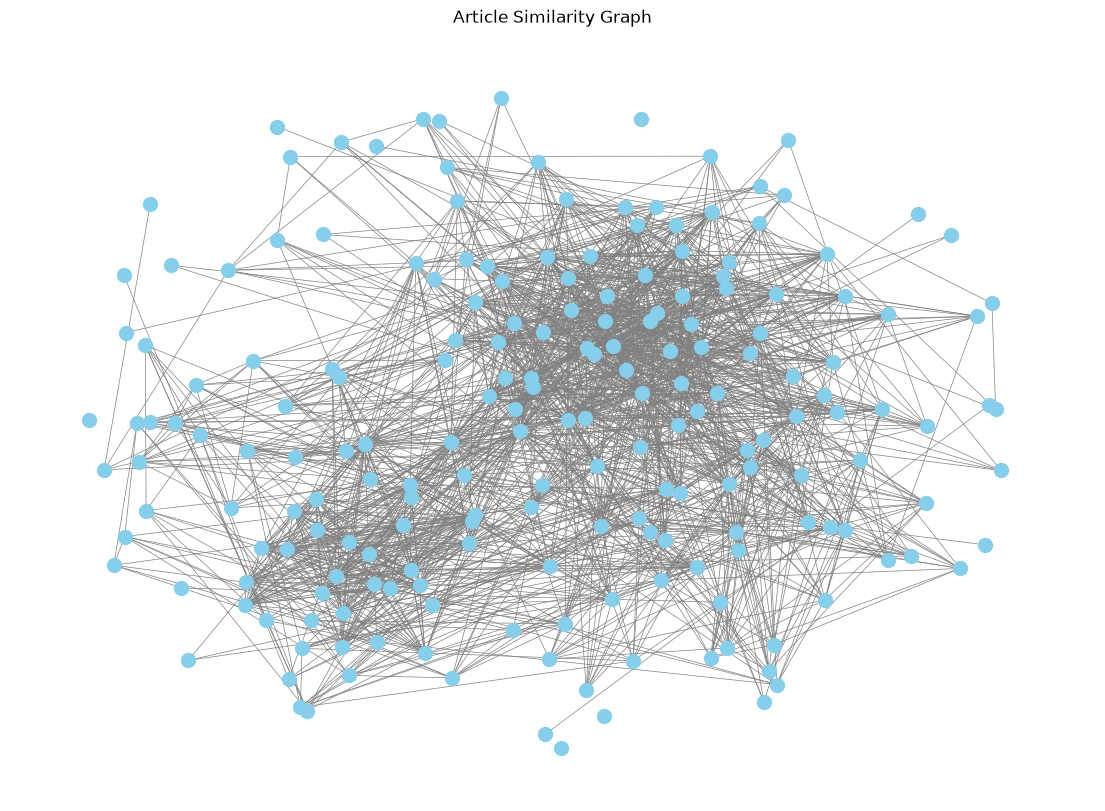

In [3]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G_similarity, seed=42, k=0.5)

nx.draw_networkx(
    G_similarity,
    pos,
    node_size=100,
    node_color="skyblue",
    edge_color="gray",
    width=0.5,
    with_labels=False
)

plt.title("Article Similarity Graph")
plt.axis("off")
plt.show()

In [4]:
G_entity = nx.Graph()
entity_article_counts = Counter()

for title, article in articles.items():
    doc = nlp(article["text"])

    article_entities = set()

    for sentence in doc.sents:
        sentence_entities = {
            ent.text.strip()
            for ent in sentence.ents
            if ent.label_ in {
                "PERSON", "ORG", "GPE", "LOC", "NORP", "EVENT", "FAC"
            }
            and len(ent.text.strip()) > 1
        }

        article_entities.update(sentence_entities)

        for entity in sentence_entities:
            G_entity.add_node(entity)

        for entity_a, entity_b in combinations(
            sorted(sentence_entities), 2
        ):
            if entity_a != entity_b:
                if G_entity.has_edge(entity_a, entity_b):
                    G_entity[entity_a][entity_b]["weight"] += 1
                else:
                    G_entity.add_edge(
                        entity_a, entity_b, weight=1
                    )

    for entity in article_entities:
        entity_article_counts[entity] += 1

nx.set_node_attributes(
    G_entity,
    dict(entity_article_counts),
    "article_count"
)

print("Entity co-occurrence graph")
print("Nodes:", G_entity.number_of_nodes())
print("Edges:", G_entity.number_of_edges())
print("Connected components:", nx.number_connected_components(G_entity))
print("Density:", round(nx.density(G_entity), 4))

Entity co-occurrence graph
Nodes: 6648
Edges: 25312
Connected components: 669
Density: 0.0011


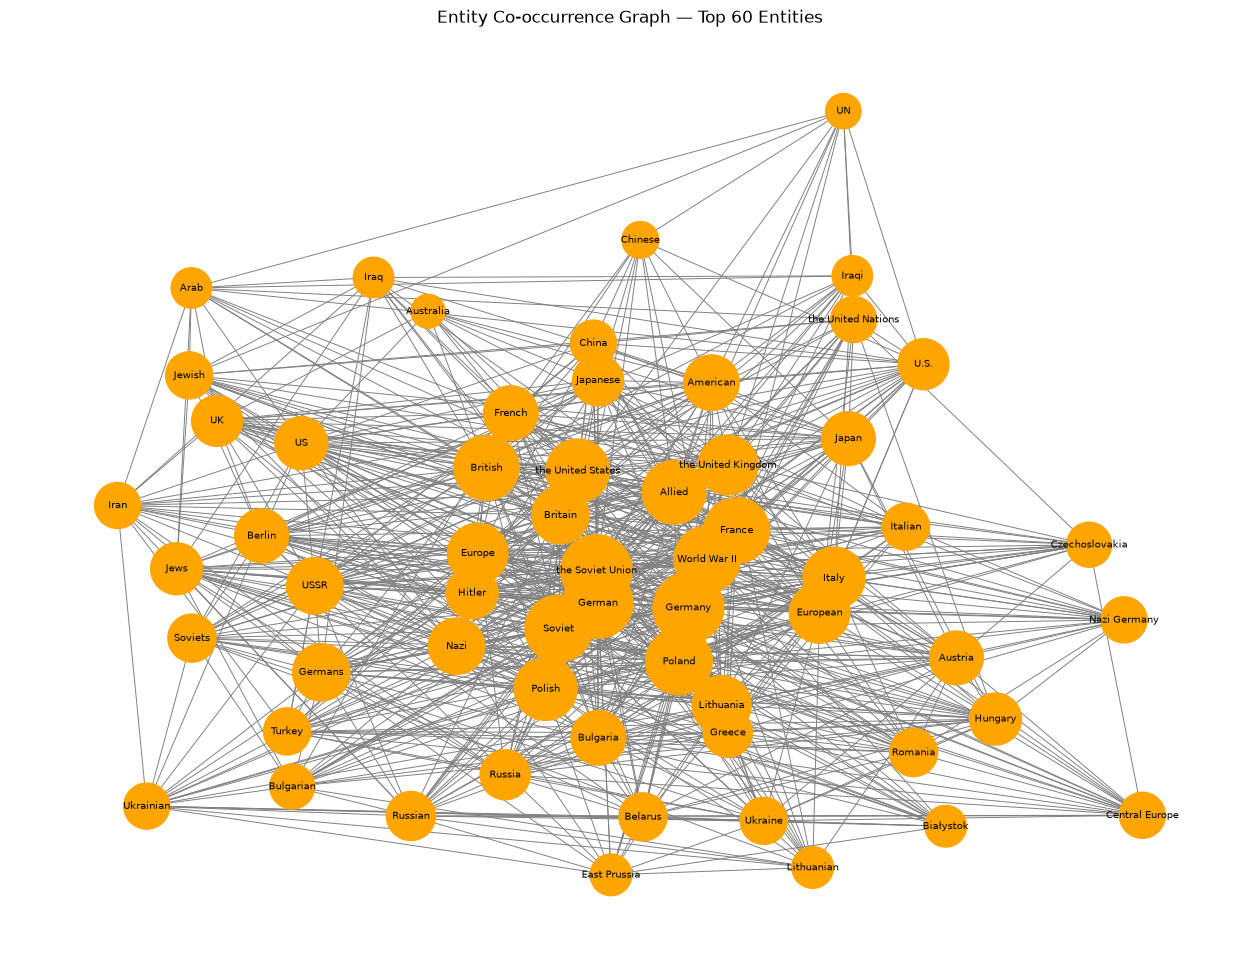

In [5]:
top_entities = sorted(
    G_entity.degree(),
    key=lambda x: x[1],
    reverse=True
)[:60]

top_nodes = [entity for entity, degree in top_entities]

G_entity_top = G_entity.subgraph(top_nodes).copy()

plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G_entity_top, seed=42, k=0.8)

node_sizes = [
    100 + 50 * G_entity_top.degree(node)
    for node in G_entity_top.nodes()
]

nx.draw_networkx(
    G_entity_top,
    pos,
    node_size=node_sizes,
    node_color="orange",
    edge_color="gray",
    width=0.7,
    font_size=7,
    with_labels=True
)

plt.title("Entity Co-occurrence Graph — Top 60 Entities")
plt.axis("off")
plt.show()

In [6]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

G_keyword = nx.Graph()
keyword_article_counts = Counter()

for title, article in articles.items():
    words = re.findall(r"\b[a-zA-Z]{3,}\b", article["text"].lower())
    words = [word for word in words if word not in ENGLISH_STOP_WORDS]

    keyword_article_counts.update(set(words))

    window_size = 5

    for i in range(len(words)):
        window = words[i:i + window_size]

        for word_a, word_b in combinations(sorted(set(window)), 2):
            if word_a == word_b:
                continue

            if G_keyword.has_edge(word_a, word_b):
                G_keyword[word_a][word_b]["weight"] += 1
            else:
                G_keyword.add_edge(word_a, word_b, weight=1)

nx.set_node_attributes(
    G_keyword,
    dict(keyword_article_counts),
    "article_count"
)

print("Keyword co-occurrence graph")
print("Nodes:", G_keyword.number_of_nodes())
print("Edges:", G_keyword.number_of_edges())
print("Connected components:", nx.number_connected_components(G_keyword))
print("Density:", round(nx.density(G_keyword), 4))

Keyword co-occurrence graph
Nodes: 13396
Edges: 260985
Connected components: 1
Density: 0.0029


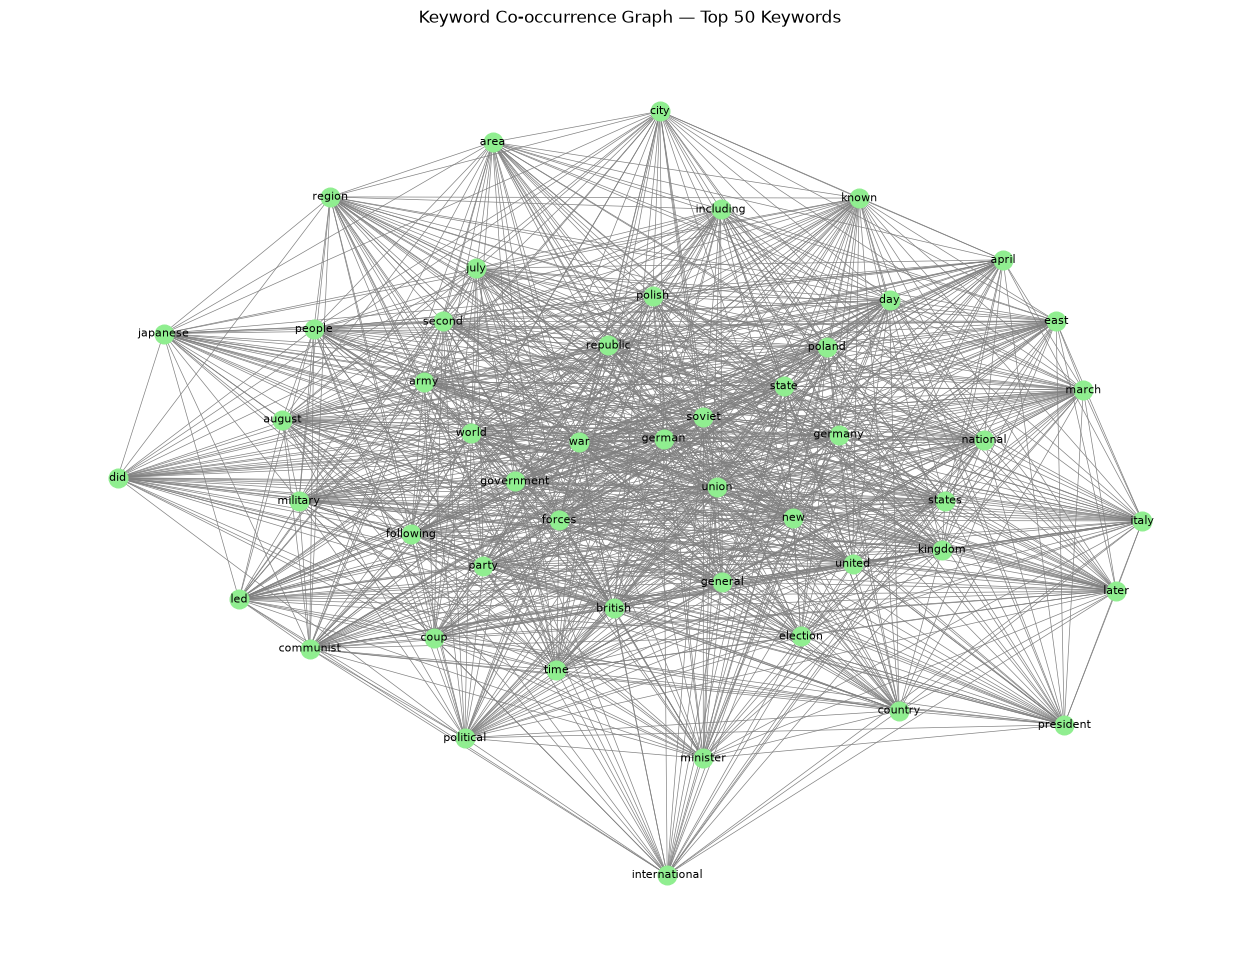

In [7]:
top_keywords = sorted(
    G_keyword.degree(),
    key=lambda x: x[1],
    reverse=True
)[:50]

top_nodes = [word for word, degree in top_keywords]
G_keyword_top = G_keyword.subgraph(top_nodes).copy()

plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G_keyword_top, seed=42, k=0.8)

nx.draw_networkx(
    G_keyword_top,
    pos,
    node_size=180,
    node_color="lightgreen",
    edge_color="gray",
    width=0.5,
    font_size=8,
    with_labels=True
)

plt.title("Keyword Co-occurrence Graph — Top 50 Keywords")
plt.axis("off")
plt.show()

In [8]:
graph_summary = pd.DataFrame([
    {
        "Graph": "Article similarity",
        "Nodes": G_similarity.number_of_nodes(),
        "Edges": G_similarity.number_of_edges(),
        "Density": nx.density(G_similarity),
        "Components": nx.number_connected_components(G_similarity)
    },
    {
        "Graph": "Entity co-occurrence",
        "Nodes": G_entity.number_of_nodes(),
        "Edges": G_entity.number_of_edges(),
        "Density": nx.density(G_entity),
        "Components": nx.number_connected_components(G_entity)
    },
    {
        "Graph": "Keyword co-occurrence",
        "Nodes": G_keyword.number_of_nodes(),
        "Edges": G_keyword.number_of_edges(),
        "Density": nx.density(G_keyword),
        "Components": nx.number_connected_components(G_keyword)
    }
])

graph_summary.round(4)

,Graph,Nodes,Edges,Density,Components
0,Article similarity,200,1831,0.0920,6
1,Entity co-occurrence,6648,25312,0.0011,669
2,Keyword co-occurrence,13396,260985,0.0029,1


In [9]:
def calculate_graph_metrics(G, graph_name):
    n = G.number_of_nodes()
    m = G.number_of_edges()

    if n == 0:
        return {
            "Graph": graph_name,
            "Nodes": 0,
            "Edges": 0,
            "Density": 0,
            "Connected Components": 0,
            "Largest Component": 0,
            "Average Degree": 0,
            "Average Clustering": 0,
            "Diameter (LCC)": None,
            "Average Shortest Path (LCC)": None
        }

    components = list(nx.connected_components(G))
    largest_nodes = max(components, key=len)
    LCC = G.subgraph(largest_nodes).copy()

    density = nx.density(G)
    average_degree = sum(dict(G.degree()).values()) / n
    clustering = nx.average_clustering(G)

    lcc_size = LCC.number_of_nodes()

    if lcc_size == 1:
        diameter = 0
        average_path = 0

    elif lcc_size <= 3000:
        diameter = nx.diameter(LCC)
        average_path = nx.average_shortest_path_length(LCC)

    else:
    
        sample_size = min(300, lcc_size)
        sample_nodes = sorted(LCC.nodes(), key=str)[:sample_size]

        distances = []
        eccentricities = []

        for source in sample_nodes:
            lengths = nx.single_source_shortest_path_length(LCC, source)
            distances.extend(lengths.values())
            eccentricities.append(max(lengths.values()))

        diameter = max(eccentricities)
        average_path = sum(distances) / len(distances)

        print(
            f"Note: distance metrics for {graph_name} "
            f"are estimated using {sample_size} source nodes.")

    return {
        "Graph": graph_name,
        "Nodes": n,
        "Edges": m,
        "Density": density,
        "Connected Components": len(components),
        "Largest Component": lcc_size,
        "Average Degree": average_degree,
        "Average Clustering": clustering,
        "Diameter (LCC)": diameter,
        "Average Shortest Path (LCC)": average_path
    }


metrics = pd.DataFrame([
    calculate_graph_metrics(G_similarity, "Article Similarity"),
    calculate_graph_metrics(G_entity, "Entity Co-occurrence"),
    calculate_graph_metrics(G_keyword, "Keyword Co-occurrence")
])

metrics.round(4)

Note: distance metrics for Entity Co-occurrence are estimated using 300 source nodes.
Note: distance metrics for Keyword Co-occurrence are estimated using 300 source nodes.


,Graph,Nodes,Edges,Density,Connected Components,Largest Component,Average Degree,Average Clustering,Diameter (LCC),Average Shortest Path (LCC)
0,Article Similarity,200,1831,0.0920,6,194,18.3100,0.5831,7,2.6308
1,Entity Co-occurrence,6648,25312,0.0011,669,5543,7.6149,0.6855,10,3.7625
2,Keyword Co-occurrence,13396,260985,0.0029,1,13396,38.9646,0.5017,6,2.7554


In [10]:
degree_centrality = nx.degree_centrality(G_entity)

betweenness_centrality = nx.betweenness_centrality(G_entity, normalized=True)

closeness_centrality = nx.closeness_centrality(G_entity)

pagerank = nx.pagerank(G_entity, weight="weight")


centrality_df = pd.DataFrame({
    "Entity": list(G_entity.nodes()),
    "Degree": [G_entity.degree(n) for n in G_entity.nodes()],
    "Degree Centrality": [
        degree_centrality[n] for n in G_entity.nodes()
    ],
    "Betweenness Centrality": [
        betweenness_centrality[n] for n in G_entity.nodes()
    ],
    "Closeness Centrality": [
        closeness_centrality[n] for n in G_entity.nodes()
    ],
    "PageRank": [pagerank[n] for n in G_entity.nodes()],
    "Articles": [
        G_entity.nodes[n].get("article_count", 0)
        for n in G_entity.nodes()
    ]
})

centrality_df = centrality_df.sort_values(
    "PageRank", ascending=False
).reset_index(drop=True)

centrality_df.head(10).round(5)

,Entity,Degree,Degree Centrality,Betweenness Centrality,Closeness Centrality,PageRank,Articles
0,German,646,0.09719,0.10081,0.36766,0.01296,74
1,Germany,429,0.06454,0.04947,0.36195,0.01038,67
2,British,424,0.06379,0.07201,0.35833,0.00850,77
3,Poland,331,0.04980,0.03326,0.34332,0.00797,39
4,the Soviet Union,330,0.04965,0.03618,0.35750,0.00698,60
5,Polish,329,0.04950,0.03080,0.33437,0.00667,32
6,Soviet,337,0.05070,0.04409,0.35008,0.00645,55
7,Italy,270,0.04062,0.03018,0.34724,0.00563,39
8,Japanese,252,0.03791,0.04284,0.32577,0.00514,25
9,France,268,0.04032,0.03228,0.35251,0.00499,49


In [11]:
print("TOP 10 — DEGREE CENTRALITY")
display(
    centrality_df.nlargest(10, "Degree Centrality")[
        ["Entity", "Degree", "Degree Centrality"]
    ]
)

print("TOP 10 — BETWEENNESS CENTRALITY")
display(
    centrality_df.nlargest(10, "Betweenness Centrality")[
        ["Entity", "Betweenness Centrality"]
    ]
)

print("TOP 10 — CLOSENESS CENTRALITY")
display(
    centrality_df.nlargest(10, "Closeness Centrality")[
        ["Entity", "Closeness Centrality"]
    ]
)

print("TOP 10 — PAGERANK")
display(
    centrality_df.nlargest(10, "PageRank")[
        ["Entity", "PageRank"]
    ]
)

TOP 10 — DEGREE CENTRALITY


,Entity,Degree,Degree Centrality
0,German,646,0.097187
1,Germany,429,0.064540
2,British,424,0.063788
6,Soviet,337,0.050700
3,Poland,331,0.049797
4,the Soviet Union,330,0.049646
5,Polish,329,0.049496
7,Italy,270,0.040620
9,France,268,0.040319
8,Japanese,252,0.037912


TOP 10 — BETWEENNESS CENTRALITY


,Entity,Betweenness Centrality
0,German,0.100806
2,British,0.072012
1,Germany,0.049475
6,Soviet,0.044086
8,Japanese,0.042843
16,American,0.042195
4,the Soviet Union,0.036178
10,the United States,0.033724
3,Poland,0.033259
9,France,0.032279


TOP 10 — CLOSENESS CENTRALITY


,Entity,Closeness Centrality
0,German,0.367656
1,Germany,0.361953
2,British,0.358332
4,the Soviet Union,0.357501
9,France,0.352510
10,the United States,0.350744
6,Soviet,0.350079
15,World War II,0.347944
7,Italy,0.347238
3,Poland,0.343316


TOP 10 — PAGERANK


,Entity,PageRank
0,German,0.012959
1,Germany,0.010378
2,British,0.008505
3,Poland,0.007974
4,the Soviet Union,0.006982
5,Polish,0.006674
6,Soviet,0.006453
7,Italy,0.005635
8,Japanese,0.005139
9,France,0.004993


In [12]:
nodes_to_keep = [
    node for node in G_entity.nodes()
    if G_entity.nodes[node].get("article_count", 0) >= 2
    and G_entity.degree(node) >= 2
]

G_entity_filtered = G_entity.subgraph(nodes_to_keep).copy()

print("Graphe original")
print("Nœuds :", G_entity.number_of_nodes())
print("Arêtes :", G_entity.number_of_edges())

print("\nGraphe filtré")
print("Nœuds :", G_entity_filtered.number_of_nodes())
print("Arêtes :", G_entity_filtered.number_of_edges())

Graphe original
Nœuds : 6648
Arêtes : 25312

Graphe filtré
Nœuds : 1094
Arêtes : 7845


In [13]:
from networkx.algorithms.community import (
    greedy_modularity_communities,
    modularity
)

greedy_communities = list(
    greedy_modularity_communities(
        G_entity_filtered,
        weight="weight"
    )
)

greedy_modularity_score = modularity(
    G_entity_filtered,
    greedy_communities,
    weight="weight"
)

print("Algorithme : Greedy Modularity")
print("Nombre de communautés :", len(greedy_communities))
print("Modularité :", round(greedy_modularity_score, 4))

print("\nLes 5 plus grandes communautés :")

for i, community_nodes in enumerate(
    sorted(greedy_communities, key=len, reverse=True)[:5],
    start=1
):
    print(f"\nCommunauté {i} — {len(community_nodes)} entités")
    print(", ".join(sorted(community_nodes)[:15]))

Algorithme : Greedy Modularity
Nombre de communautés : 26
Modularité : 0.4276

Les 5 plus grandes communautés :

Communauté 1 — 325 entités
2nd Panzer Army, 3rd Ukrainian Front, ACC, Adolf Hitler, Aegean, Algeria, Allied Expeditionary Force, Andrei Zhdanov, Anschluss, Antanas Smetona, Arkhangelsk, Armistice, Army Group Centre, Associated Powers, Augustinas Voldemaras

Communauté 2 — 217 entités
9 September 1944, Abyssinia, Albania, Albanian, Albert Speer, Aleksandar Stamboliyski, Alexander, Allied, Alps, Ankara, Army, Athens, Avars, Axis, BANU

Communauté 3 — 211 entités
ANZUS, AUSCANNZUKUS, Africa, Air, Air Force, America, Americans, Anhui, Asia, Asian, Atlantic, Australia, Australian, Awami League, Bangladesh

Communauté 4 — 159 entités
Abd al-Ilah, Abd al-Qadir al-Husayni, Abdul Salam Arif, Afghanistan, Alaska, American, Americas, Amin al-Husseini, Anglo, Anthony Eden, Arab, Arabic, Arabs, Argentina, Arif

Communauté 5 — 97 entités
Addington, African, Archibald S. Foord, B.M. Walker

In [14]:
import community as community_louvain
from networkx.algorithms.community import modularity


louvain_partition = community_louvain.best_partition(
    G_entity_filtered,
    weight="weight",
    random_state=42
)


louvain_communities_dict = {}

for node, community_id in louvain_partition.items():
    louvain_communities_dict.setdefault(
        community_id, set()
    ).add(node)

louvain_communities = list(
    louvain_communities_dict.values()
)


louvain_modularity_score = modularity(
    G_entity_filtered,
    louvain_communities,
    weight="weight"
)

print("Algorithme : Louvain")
print("Nombre de communautés :", len(louvain_communities))
print("Modularité :", round(louvain_modularity_score, 4))

print("\nLes 5 plus grandes communautés :")

for i, community_nodes in enumerate(
    sorted(louvain_communities, key=len, reverse=True)[:5],
    start=1
):
    print(f"\nCommunauté {i} — {len(community_nodes)} entités")
    print(", ".join(sorted(community_nodes)[:15]))

Algorithme : Louvain
Nombre de communautés : 25
Modularité : 0.4351

Les 5 plus grandes communautés :

Communauté 1 — 195 entités
2nd Panzer Army, 3rd Ukrainian Front, Adolf Hitler, Albert Speer, Algeria, Allied Expeditionary Force, Andrei Zhdanov, Anglo, Ankara, Anschluss, Argentina, Arkhangelsk, Armistice, Army Group Centre, Austria

Communauté 2 — 162 entités
ACC, Aegean, Antanas Smetona, Associated Powers, Augustinas Voldemaras, Auschwitz, BNR, Baltic, Belarus, Belarusian, Belarusians, Belorussia, Bessarabia, Bezirk Bialystok, Bialystok

Communauté 3 — 145 entités
ANZUS, AUSCANNZUKUS, Afghanistan, Air, Air Force, America, American, Americans, Anthony Eden, Ashgate Publishing Ltd External, Ashgate Publishing Ltd Walker, Asian, Attlee, Australia, Australian

Communauté 4 — 127 entités
9 September 1944, Albania, Albanian, Aleksandar Stamboliyski, Alexander, Avars, BANU, BCP, BKP, Balkan, Balkans, Belgrade, Black Ruthenia, Bohemia, Boris III

Communauté 5 — 122 entités
Adams, Addington

In [15]:
community_comparison = pd.DataFrame([
    {
        "Algorithme": "Greedy Modularity",
        "Nombre de communautés": len(greedy_communities),
        "Modularité": greedy_modularity_score
    },
    {
        "Algorithme": "Louvain",
        "Nombre de communautés": len(louvain_communities),
        "Modularité": louvain_modularity_score
    }
])

display(community_comparison.round(4))

,Algorithme,Nombre de communautés,Modularité
0,Greedy Modularity,26,0.4276
1,Louvain,25,0.4351


In [16]:
from itertools import combinations

top_degree_entities = [
    entity
    for entity, degree in sorted(
        G_entity.degree(),
        key=lambda item: item[1],
        reverse=True
    )[:10]
]

print("Top 10 entities by degree:")
for entity in top_degree_entities:
    print(f"{entity}: degree = {G_entity.degree(entity)}")

Top 10 entities by degree:
German: degree = 646
Germany: degree = 429
British: degree = 424
Soviet: degree = 337
Poland: degree = 331
the Soviet Union: degree = 330
Polish: degree = 329
Italy: degree = 270
France: degree = 268
Japanese: degree = 252


In [17]:
path_results = []

candidate_pairs = list(
    combinations(top_degree_entities, 2)
)[:6]

for source, target in candidate_pairs:
    if nx.has_path(G_entity, source, target):
        path = nx.shortest_path(
            G_entity,
            source=source,
            target=target
        )

        path_results.append({
            "Source": source,
            "Target": target,
            "Path Length": len(path) - 1,
            "Path": " → ".join(path)
        })
    else:
        path_results.append({
            "Source": source,
            "Target": target,
            "Path Length": None,
            "Path": "No path (different components)"
        })

path_df = pd.DataFrame(path_results)
display(path_df)

,Source,Target,Path Length,Path
0,German,Germany,1,German → Germany
1,German,British,1,German → British
2,German,Soviet,1,German → Soviet
3,German,Poland,1,German → Poland
4,German,the Soviet Union,1,German → the Soviet Union
5,German,Polish,1,German → Polish


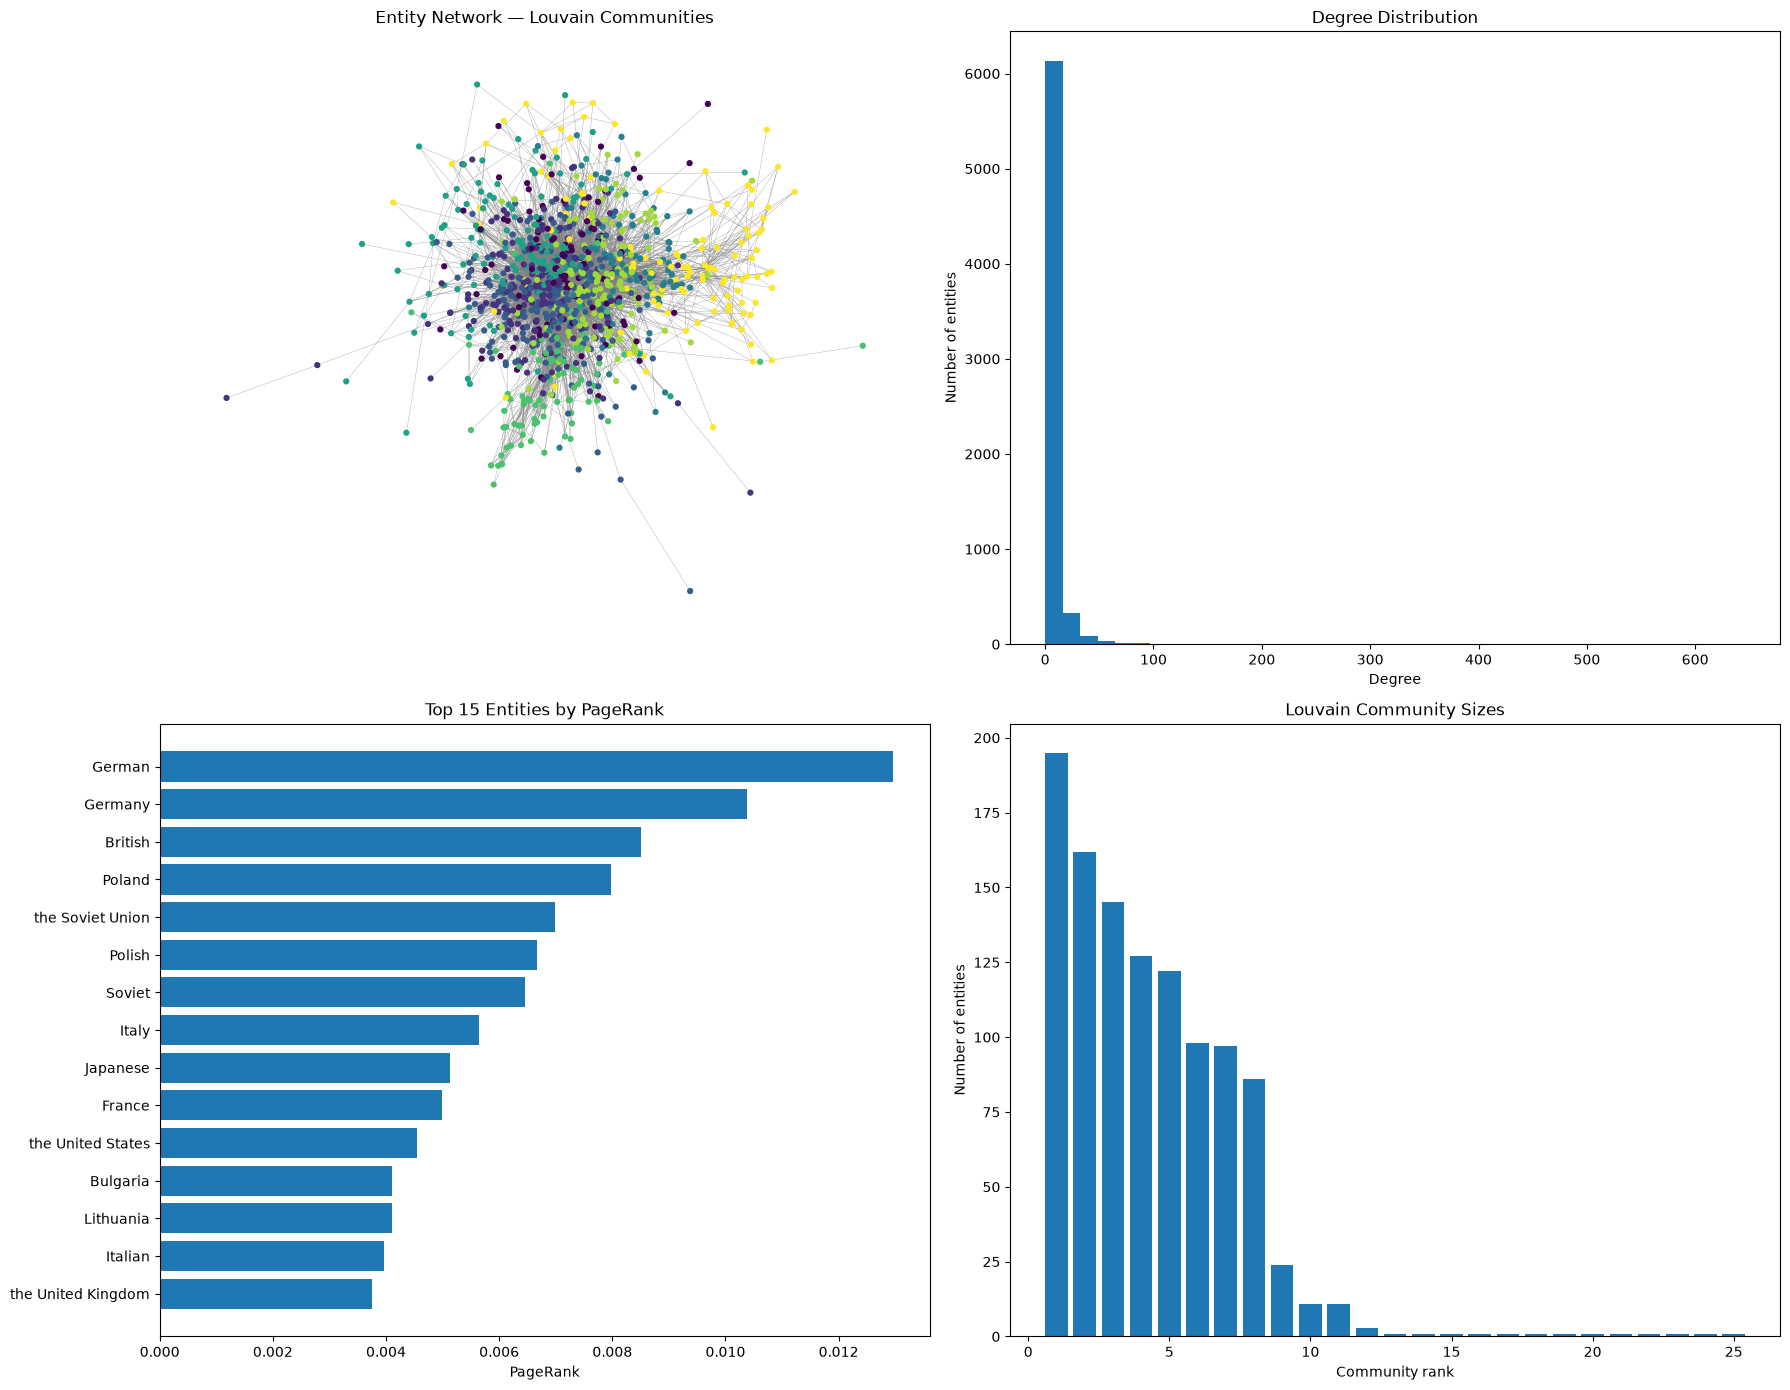

Dashboard saved: miniproject_dashboard.png


In [18]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(18, 14))


ax = axes[0, 0]

largest_community_ids = sorted(
    louvain_communities_dict,
    key=lambda cid: len(louvain_communities_dict[cid]),
    reverse=True
)[:8]

display_nodes = set()
for cid in largest_community_ids:
    display_nodes.update(louvain_communities_dict[cid])

G_display = G_entity_filtered.subgraph(display_nodes).copy()

display_partition = {
    node: louvain_partition[node]
    for node in G_display.nodes()
}

community_ids = sorted(set(display_partition.values()))
community_color = {
    cid: i for i, cid in enumerate(community_ids)
}

node_colors = [
    community_color[display_partition[node]]
    for node in G_display.nodes()
]

pos = nx.spring_layout(G_display, seed=42)

nx.draw_networkx(
    G_display,
    pos,
    ax=ax,
    node_size=12,
    node_color=node_colors,
    edge_color="gray",
    width=0.2,
    with_labels=False
)

ax.set_title("Entity Network — Louvain Communities")
ax.axis("off")


ax = axes[0, 1]

degrees = [degree for _, degree in G_entity.degree()]
ax.hist(degrees, bins=40)
ax.set_title("Degree Distribution")
ax.set_xlabel("Degree")
ax.set_ylabel("Number of entities")


ax = axes[1, 0]

top15 = centrality_df.nlargest(15, "PageRank").sort_values("PageRank")

ax.barh(top15["Entity"], top15["PageRank"])
ax.set_title("Top 15 Entities by PageRank")
ax.set_xlabel("PageRank")


ax = axes[1, 1]

community_sizes = sorted(
    [len(c) for c in louvain_communities],
    reverse=True
)

ax.bar(range(1, len(community_sizes) + 1), community_sizes)
ax.set_title("Louvain Community Sizes")
ax.set_xlabel("Community rank")
ax.set_ylabel("Number of entities")

plt.tight_layout()
plt.savefig(
    "miniproject_dashboard.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Dashboard saved: miniproject_dashboard.png")

In [19]:
centrality_df.to_csv(
    "entity_centrality_results.csv",
    index=False,
    encoding="utf-8"
)

print("CSV saved: entity_centrality_results.csv")
print("Number of entities:", len(centrality_df))

CSV saved: entity_centrality_results.csv
Number of entities: 6648


In [20]:

from pyvis.network import Network
import networkx as nx
import spacy
import os

pagerank_values = nx.pagerank(G_entity, weight="weight")


top_nodes = sorted(
    G_entity.degree(),
    key=lambda item: item[1],
    reverse=True
)[:200]

selected_nodes = [node for node, degree in top_nodes]
G_interactive = G_entity.subgraph(selected_nodes).copy()


net = Network(
    height="750px",
    width="100%",
    bgcolor="#ffffff",
    font_color="black",
    notebook=False,
    directed=False
)

net.barnes_hut()


nlp = spacy.load("en_core_web_sm")

entity_colors = {
    "PERSON": "#e74c3c",
    "ORG": "#3498db",
    "GPE": "#2ecc71",
    "LOC": "#f39c12",
    "EVENT": "#9b59b6",
    "NORP": "#1abc9c",
    "OTHER": "#95a5a6"
}

for node in G_interactive.nodes():
    doc = nlp(node)
    entity_type = doc.ents[0].label_ if doc.ents else "OTHER"

    size = 10 + pagerank_values.get(node, 0) * 3000

    net.add_node(
        node,
        label=node,
        title=f"Entity: {node}<br>Type: {entity_type}<br>"
              f"Degree: {G_entity.degree(node)}<br>"
              f"PageRank: {pagerank_values.get(node, 0):.5f}",
        color=entity_colors.get(entity_type, entity_colors["OTHER"]),
        size=size
    )


for source, target, data in G_interactive.edges(data=True):
    net.add_edge(
        source,
        target,
        value=data.get("weight", 1)
    )


output_file = "miniproject_interactive.html"
net.save_graph(output_file)

print("Graphe interactif créé :", output_file)
print("Nombre de nœuds :", G_interactive.number_of_nodes())
print("Nombre d'arêtes :", G_interactive.number_of_edges())
print("Fichier présent :", os.path.exists(output_file))


Graphe interactif créé : miniproject_interactive.html
Nombre de nœuds : 200
Nombre d'arêtes : 2780
Fichier présent : True
